# Accordion lattice: from the beam angle to the trap frequencies

You give this notebook the laboratory parameters — wavelength, angle between
the beams, power and waists, atom number, scattering length and temperature —
and it returns:

1. the **lattice period** and the **recoil energy**;
2. the **axial frequency** of one site, both from the harmonic formula and from
   the exact band structure, together with the size of the error you make by
   using the harmonic one;
3. the **three trap frequencies**, because the trap is an ellipsoid, with the
   two relevant means and the shape of the cloud you see on the camera;
4. the **two-dimensionality test**: chemical potential and temperature against
   the axial level spacing;
5. the **effective in-plane interaction** and the phase-space density, which is
   what locates the Berezinskii-Kosterlitz-Thouless transition.

Only **one** cell needs editing, the parameter cell. Everything else runs on
its own.

Requires only `numpy`, `scipy` and `matplotlib`.

> All the arithmetic is in SI units. The printed output is converted to the
> units used at the bench (micrometre, kilohertz, nanokelvin).

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal

# works across numpy versions
trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

# ------------------------------------------------- physical constants
hbar = 1.054571817e-34          # J s
kB   = 1.380649e-23             # J/K
c    = 2.99792458e8             # m/s
eps0 = 8.8541878128e-12         # F/m
amu  = 1.66053906660e-27        # kg
a0   = 5.29177210903e-11        # m  (Bohr radius)

m_K39 = 38.9637064864 * amu     # mass of potassium-39

# ------------------------------------------------- potassium-39 D lines
# One linewidth shared by both lines, with the line-strength weights 1 (D1)
# and 2 (D2). Giving each line its own natural linewidth AND the 2:1 weight
# counts the oscillator strength twice and overestimates the depth threefold.
# The check below catches exactly that.
LAM_D1, LAM_D2 = 770.108e-9, 766.701e-9
GAMMA_D = 2 * math.pi * 6.0e6

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Laboratory parameters

**This is the only cell you need to edit.**

On the angle: `full_angle_deg` is the angle **between the two beams**. An
accordion lattice works by changing it, and that is what sets the period.

On the in-plane frequencies: by default the notebook estimates them from the
beam waists, assuming the Gaussian envelope does the confining. In a real
accordion one in-plane direction is usually confined by the Rayleigh range,
which is far weaker, or by an auxiliary trap. **If you have measured the
in-plane frequencies, put them in `measured_plane_freq_Hz` and the notebook
uses your numbers instead of the estimate.**

In [2]:
# ------------------------------------------------- beams and geometry
laser_wavelength    = 1064e-9    # m
full_angle_deg      = 20.0       # degrees, angle BETWEEN the two beams
power_per_beam      = 0.1        # W
waist_x             = 200e-6     # m
waist_y             = 200e-6     # m

# If you know the lattice depth, give it in units of the recoil energy and the
# estimate from the beam power is skipped. Leave None to compute it.
depth_in_ER         = None       # e.g. 30.0

# Dynamic polarizability at the laser wavelength, in atomic units. Leave None
# and it is computed from the two D lines, which is a stand-in good to a few
# per cent; a published value is better. The notebook prints both.
polarizability_au   = None       # e.g. 592.0

# If you measured the in-plane trap frequencies, give (f_x, f_y) in hertz.
# Leave None to let the notebook estimate them from the waists.
measured_plane_freq_Hz = None    # e.g. (40.0, 40.0)

# ------------------------------------------------- the sample
atom_number         = 1e4
temperature_nK      = 8.0        # nK

# Give either the scattering length directly, or the magnetic field and let
# the Feshbach parametrisation below convert it. The field wins if both are set.
scattering_length   = 30 * a0    # m
magnetic_field_G    = None       # G, e.g. 395.0

# In-plane geometry: "harmonic" uses the trap frequencies; "box" uses a flat
# disc of the radius below, which is what a digital micromirror device makes.
in_plane_geometry   = "harmonic"
box_radius          = 20e-6      # m, only used when the geometry is "box"

# ------------------------------------------------- transition constant
# Critical phase-space density of the Berezinskii-Kosterlitz-Thouless
# transition in a weakly interacting two-dimensional Bose gas,
# D_c = ln(xi/g_tilde). CHECK the value of xi against its source before using
# any result that depends on it in something published.
xi_bkt = 380.0

## 2. Lattice geometry

Two beams of wavelength $\lambda$ crossing at a full angle $2\theta$ build a
standing wave along the bisector, of period

$$ d = \frac{\lambda}{2\sin\theta} . $$

The lattice wavevector is $k = \pi/d$ and the natural energy scale is the
**recoil energy**, the kinetic energy an atom picks up by absorbing one lattice
photon:

$$ E_R = \frac{\hbar^2 k^2}{2m} . $$

Lattice depths are always quoted in units of it, $V_0 = s\,E_R$. That single
number $s$ describes the lattice; everything else follows from it.

If the depth is not supplied, it is estimated from the power. Two beams of peak
intensity $I_1$ each interfere up to $4I_1$, so $V_0 = 4\,|U(I_1)|$ with $U$ the
dipole potential.

In [3]:
def polarizability(lam_laser):
    # Dynamic polarizability from the two D lines, in atomic units.
    w = 2 * math.pi * c / lam_laser
    acc = 0.0
    for lam0, weight in ((LAM_D1, 1.0), (LAM_D2, 2.0)):
        w0 = 2 * math.pi * c / lam0
        acc += weight * (1.0 / w0 ** 3) * (1.0 / (w0 - w) + 1.0 / (w0 + w))
    U_over_I = -(math.pi * c ** 2 / 2.0) * GAMMA_D * acc
    return -2 * eps0 * c * U_over_I / (4 * math.pi * eps0 * a0 ** 3)


def dipole_potential(I, alpha_au):
    # U = - alpha I / (2 eps0 c); negative for red detuning.
    alpha_SI = alpha_au * 4 * math.pi * eps0 * a0 ** 3
    return -alpha_SI * I / (2 * eps0 * c)


def feshbach_a(B_gauss):
    # a(B) = a_bg [1 - Delta/(B - B0)] for the broad potassium-39 resonance.
    # CHECK the three numbers against D'Errico et al., New J. Phys. 9, 223
    # (2007) before using them for anything but a first estimate.
    a_bg, B0, Delta = -29.0 * a0, 403.4, -52.0
    return a_bg * (1.0 - Delta / (B_gauss - B0))


theta = math.radians(full_angle_deg) / 2.0
d_lat = laser_wavelength / (2 * math.sin(theta))
k_lat = math.pi / d_lat
E_R = hbar ** 2 * k_lat ** 2 / (2 * m_K39)

alpha_model = polarizability(laser_wavelength)
alpha_used = alpha_model if polarizability_au is None else float(polarizability_au)

if depth_in_ER is None:
    I1 = 2 * power_per_beam / (math.pi * waist_x * waist_y)
    V0 = 4 * abs(dipole_potential(I1, alpha_used))
    s_lat = V0 / E_R
    depth_origin = "from the beam power"
else:
    s_lat = float(depth_in_ER)
    V0 = s_lat * E_R
    depth_origin = "supplied"

if magnetic_field_G is not None:
    scattering_length = feshbach_a(float(magnetic_field_G))

print("polarizability check: the model gives %.0f a.u. in the static limit,"
      % polarizability(1.0))
print("   against the published value near 290 a.u. for potassium.")
print("polarizability used at %.0f nm = %.0f a.u.%s"
      % (laser_wavelength * 1e9, alpha_used,
         "" if polarizability_au is None else "   (supplied)"))
if magnetic_field_G is not None:
    print("scattering length at %.1f G = %+.1f a0"
          % (magnetic_field_G, scattering_length / a0))
print()
print("lattice period         d = %9.3f um" % (d_lat * 1e6))
print("recoil energy      E_R/h = %9.3f kHz" % (E_R / hbar / 2 / math.pi / 1e3))
print("lattice depth        V_0 = %9.2f E_R   (%s)" % (s_lat, depth_origin))
print("                   V_0/h = %9.2f kHz" % (V0 / hbar / 2 / math.pi / 1e3))
print("                 V_0/k_B = %9.2f uK" % (V0 / kB * 1e6))

polarizability check: the model gives 284 a.u. in the static limit,
   against the published value near 290 a.u. for potassium.
polarizability used at 1064 nm = 592 a.u.

lattice period         d =     3.064 um
recoil energy      E_R/h =     0.136 kHz
lattice depth        V_0 =    129.62 E_R   (from the beam power)
                   V_0/h =     17.68 kHz
                 V_0/k_B =      0.85 uK


## 3. The axial frequency, harmonic and exact

Near the bottom of a site, $V_0\sin^2(kz)\approx V_0k^2z^2$, which gives the
formula everyone uses:

$$ \hbar\omega_z = 2\sqrt{s}\,E_R . $$

It is an **approximation**. The real site is anharmonic, and the spacing
between its two lowest levels is smaller than the harmonic value. The notebook
solves the exact band structure — diagonalising the sinusoidal potential in a
plane-wave basis — and compares the two.

Rule of thumb: the harmonic formula is fine for a deep lattice and poor for a
shallow one. Below roughly $s\approx 10$ you want the exact frequency.

Two honest limits of what is computed here. For a shallow lattice the first
excited band is no longer flat, so "the axial frequency" stops being a single
number and the gap taken at zero quasimomentum is only the bottom of a band.
And the site wavefunction is obtained by putting walls at the maxima, which is
a good stand-in for the true localised state when the lattice is deep and a
rough one when it is not.

In [4]:
def band_energies(s, q=0.0, nmax=25, how_many=3):
    # Band energies, in units of E_R, at quasimomentum q (in units of k).
    n = np.arange(-nmax, nmax + 1)
    diag = (q + 2 * n) ** 2 + s / 2.0
    offd = -s / 4.0 * np.ones(len(n) - 1)
    return eigh_tridiagonal(diag, offd, select="i",
                            select_range=(0, how_many - 1))[0]


def single_site(s, n=4000):
    # Ground state of one isolated site, with walls at the maxima. Returns the
    # energy (in E_R), the interaction correction factor R, and (z, u) for
    # plotting. R < 1 always: the true wavefunction is wider than the Gaussian,
    # so the effective interaction is weaker than the naive formula gives.
    L = math.pi
    h = L / (n + 1)
    z = -L / 2 + h * np.arange(1, n + 1)
    diag = 2.0 / h ** 2 + s * np.sin(z) ** 2
    offd = -np.ones(n - 1) / h ** 2
    val, vec = eigh_tridiagonal(diag, offd, select="i", select_range=(0, 0))
    u = vec[:, 0]
    u = u / math.sqrt(trapz(u ** 2, z))
    I4 = float(trapz(u ** 4, z))          # integral of |phi|^4, in units of k
    R = math.sqrt(2 * math.pi) * I4 / s ** 0.25
    return val[0], R, I4, z, u


bands = band_energies(s_lat)
w_z_exact = (bands[1] - bands[0]) * E_R / hbar
w_z_harm = 2 * math.sqrt(s_lat) * E_R / hbar
_, R_site, I4_site, z_site, u_site = single_site(s_lat)

l_z = math.sqrt(hbar / (m_K39 * w_z_exact))

print("axial frequency, harmonic  f_z = %9.3f kHz" % (w_z_harm / 2 / math.pi / 1e3))
print("axial frequency, exact     f_z = %9.3f kHz" % (w_z_exact / 2 / math.pi / 1e3))
print("error of the harmonic formula  = %+8.2f %%"
      % (100 * (w_z_harm / w_z_exact - 1)))
print("oscillator length          l_z = %9.1f nm" % (l_z * 1e9))
print("interaction correction       R = %9.4f" % R_site)

axial frequency, harmonic  f_z =     3.106 kHz
axial frequency, exact     f_z =     2.962 kHz
error of the harmonic formula  =    +4.83 %
oscillator length          l_z =     295.9 nm
interaction correction       R =    0.9799


## 3b. Calibrating the depth by amplitude modulation

Shaking the lattice depth drives transitions between bands, and this is how a
depth is measured in practice. One point decides whether the measurement is
read correctly: modulating the depth keeps the potential symmetric, so the
perturbation is even and it can only connect states of the **same parity**.
The first excited band has the wrong parity. The resonance you see is therefore
the transition from the lowest band to the **second** one, not to the first.

So the peak in an amplitude-modulation scan is **not** the trap frequency. In a
deep lattice it sits near twice it; in a shallow one, nowhere near. The cell
below gives the frequency to look for, from the exact bands, and shows how
wrong the two usual shortcuts are.

In [5]:
f_mod = (band_energies(s_lat, how_many=3)[2] - bands[0]) * E_R / hbar / 2 / math.pi

print("amplitude-modulation resonance to look for = %9.3f kHz" % (f_mod / 1e3))
print()
print("if you read that peak as the trap frequency:        off by %+6.1f %%"
      % (100 * (f_mod / (w_z_exact / 2 / math.pi) - 1)))
print("if you read it as twice the trap frequency:         off by %+6.1f %%"
      % (100 * (f_mod / (2 * w_z_exact / 2 / math.pi) - 1)))
print()
print("deep-lattice shortcut 2 f_z - E_R/2h               = %9.3f kHz  (%+.1f %%)"
      % ((2 * w_z_exact / 2 / math.pi - E_R / hbar / 4 / math.pi) / 1e3,
         100 * ((2 * w_z_exact / 2 / math.pi - E_R / hbar / 4 / math.pi) / f_mod - 1)))

amplitude-modulation resonance to look for =     5.771 kHz

if you read that peak as the trap frequency:        off by  +94.8 %
if you read it as twice the trap frequency:         off by   -2.6 %

deep-lattice shortcut 2 f_z - E_R/2h               =     5.857 kHz  (+1.5 %)


## 4. What comes out ellipsoidal

The resulting trap is not round: it is a very flat ellipsoid. The lattice
direction is extremely tight and the two in-plane directions are loose. The
three frequencies are what characterise everything.

Two means show up, and they are **not** the same thing:

- the **geometric mean** $\bar\omega=(\omega_x\omega_y\omega_z)^{1/3}$ is the
  one that enters the critical temperature and the counting of states;
- the **quadratic mean**
  $\omega_{\rm ef}=\sqrt{(\omega_x^2+\omega_y^2+\omega_z^2)/3}$ is the one that
  governs the symmetric sector of the excitations.

The trap deformation collapses into a single dimensionless invariant

$$ s_{\rm def} = \sum_a \left(\frac{\omega_a^2-\omega_{\rm ef}^2}{\omega_{\rm ef}^2}\right)^2 , $$

which vanishes only when the three frequencies are equal. In an accordion it is
large, because the ellipsoid is extreme — it is the number that says how far
from round you are.

The cloud on the camera has radii going as the inverse of each frequency, so
the aspect ratio of the image is read straight off these numbers.

In [6]:
if measured_plane_freq_Hz is None:
    # Atoms sit at an antinode of the standing wave, where the envelope is at
    # its full depth V_0 - not V_0/2, which would be the depth averaged over a
    # period and is the wrong thing to confine with.
    w_x = math.sqrt(4 * V0 / (m_K39 * waist_x ** 2))
    w_y = math.sqrt(4 * V0 / (m_K39 * waist_y ** 2))
    plane_origin = "estimated from the waists"
else:
    w_x = 2 * math.pi * measured_plane_freq_Hz[0]
    w_y = 2 * math.pi * measured_plane_freq_Hz[1]
    plane_origin = "measured"

w = np.array([w_x, w_y, w_z_exact])

w_geo = float(np.prod(w) ** (1 / 3))
w_ef = float(math.sqrt((w ** 2).mean()))
s_def = float((((w ** 2 - w_ef ** 2) / w_ef ** 2) ** 2).sum())

print("trap frequencies (in-plane values %s):" % plane_origin)
for name, wa in zip("xyz", w):
    print("   f_%s = %11.3f Hz" % (name, wa / 2 / math.pi))
print()
print("geometric mean      fbar = %11.3f Hz" % (w_geo / 2 / math.pi))
print("quadratic mean      f_ef = %11.3f Hz" % (w_ef / 2 / math.pi))
print("aspect ratio     f_z/f_x = %11.1f" % (w[2] / w[0]))
print("deformation invariant    = %11.2f" % s_def)
print()
print("ground-state size along each axis (root mean square radius):")
for name, wa in zip("xyz", w):
    print("   sigma_%s = %9.3f um" % (name,
          math.sqrt(hbar / (2 * m_K39 * wa)) * 1e6))

trap frequencies (in-plane values estimated from the waists):
   f_x =      21.415 Hz
   f_y =      21.415 Hz
   f_z =    2962.353 Hz

geometric mean      fbar =     110.753 Hz
quadratic mean      f_ef =    1710.405 Hz
aspect ratio     f_z/f_x =       138.3
deformation invariant    =        6.00

ground-state size along each axis (root mean square radius):
   sigma_x =     2.461 um
   sigma_y =     2.461 um
   sigma_z =     0.209 um


## 5. Is it really two-dimensional?

Two-dimensional means that **nothing has enough energy to climb the first step
along the tight direction**. Two conditions, and both must hold:

$$ \mu \ll \hbar\omega_z \qquad\text{and}\qquad k_BT \ll \hbar\omega_z . $$

The first says the interaction does not push anyone up; the second, that
thermal agitation does not either. If only one holds, the gas sits in an
intermediate regime, neither three- nor two-dimensional.

The effective in-plane interaction is dimensionless,

$$ \tilde g = \sqrt{8\pi}\,\frac{a}{\ell_z}\,R , $$

with $R$ the correction computed above, and the chemical potential of a
two-dimensional gas in a harmonic in-plane trap is

$$ \mu = \hbar\omega_\perp\sqrt{\frac{N\tilde g}{\pi}},
   \qquad \omega_\perp=\sqrt{\omega_x\omega_y} . $$

One limit to keep in sight: the expression above is the weak-confinement
result, valid while the scattering length stays small compared with the axial
oscillator length. Near a Feshbach resonance that stops being true, and the
two-dimensional coupling acquires a confinement correction which is not a
simple factor — it depends on the collision energy through a logarithm. The
cell below prints the ratio and warns when it leaves the safe range. Do not
patch it with a one-dimensional confinement-induced-resonance formula; those
look similar and are not the same thing.

That $\mu$ is the zero-temperature expression. Comparing the phase-space
density built from it against the transition criterion therefore **places** the
sample on one side or the other; it is not an equation of state and it is not
a measurement of the transition. Treat the last two lines of output as an
order of magnitude, not as a number to quote.

In [7]:
# computed straight from the integral, so the axial profile enters once and
# only once; the sqrt(8 pi) a / l_z form is its Gaussian limit
g_tilde = 4 * math.pi * scattering_length * k_lat * I4_site
w_perp = math.sqrt(w_x * w_y)
T = temperature_nK * 1e-9

if in_plane_geometry == "box":
    n0 = atom_number / (math.pi * box_radius ** 2)      # flat disc
    mu = hbar ** 2 * g_tilde * n0 / m_K39
else:
    mu = hbar * w_perp * math.sqrt(atom_number * g_tilde / math.pi)
    n0 = mu * m_K39 / (hbar ** 2 * g_tilde)             # central areal density

razao = scattering_length / l_z
print("scattering length / axial length    = %10.4f%s" % (razao,
      "" if abs(razao) < 0.1 else
      "   WARNING: the weak-confinement formula below is leaving its range"))
print("effective in-plane interaction  g~ = %10.4f" % g_tilde)
print("chemical potential            mu/h = %10.3f Hz   (%s in plane)"
      % (mu / hbar / 2 / math.pi, in_plane_geometry))
print()
print("   mu / hbar w_z    = %9.4f   %s" % (mu / (hbar * w_z_exact),
      "OK" if mu < 0.1 * hbar * w_z_exact else "WARNING: not two-dimensional"))
print("   k_B T / hbar w_z = %9.4f   %s" % (kB * T / (hbar * w_z_exact),
      "OK" if kB * T < 0.1 * hbar * w_z_exact else "WARNING: not two-dimensional"))

# central phase-space density against the transition criterion
lam_T = hbar * math.sqrt(2 * math.pi / (m_K39 * kB * T))
D0 = n0 * lam_T ** 2
D_c = math.log(xi_bkt / g_tilde)

print()
print("central phase-space density   D = %9.2f" % D0)
print("transition criterion        D_c = %9.2f   (depends on xi)" % D_c)
print("   ->", "superfluid side" if D0 > D_c else "normal side")

scattering length / axial length    =     0.0054
effective in-plane interaction  g~ =     0.0270
chemical potential            mu/h =    198.465 Hz   (harmonic in plane)

   mu / hbar w_z    =    0.0670   OK
   k_B T / hbar w_z =    0.0563   OK

central phase-space density   D =    277.24
transition criterion        D_c =      9.55   (depends on xi)
   -> superfluid side


## 6. The design curves

The first figure is the one you use to pick the angle: period and axial
frequency on the left, and the two-dimensionality test on the right — both
ratios have to sit well below the dashed line.

The second shows why the harmonic approximation will not do for a shallow
lattice: the real well is wider than the parabola, and the ground state
notices.

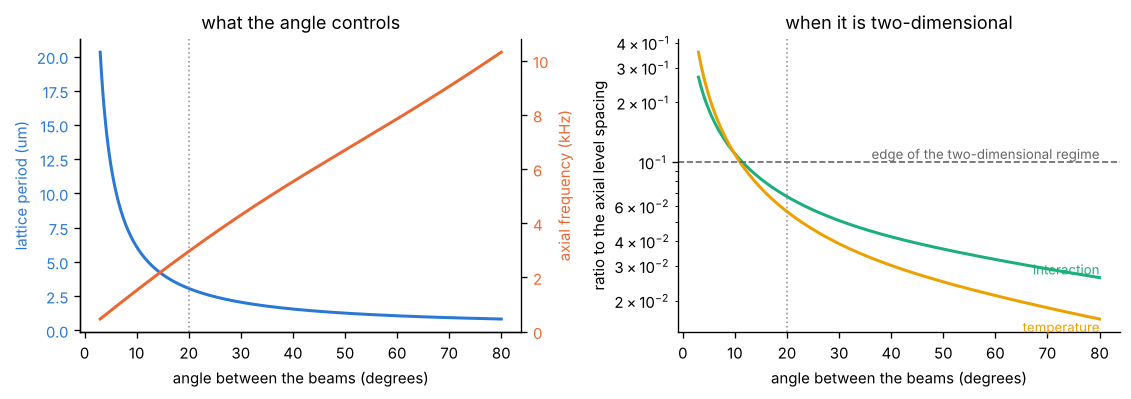

In [8]:
angles = np.linspace(3.0, 80.0, 300)
period, fz, ratio_mu, ratio_T = [], [], [], []
for ang in angles:
    th = math.radians(ang) / 2.0
    d_ = laser_wavelength / (2 * math.sin(th))
    k_ = math.pi / d_
    ER_ = hbar ** 2 * k_ ** 2 / (2 * m_K39)
    s_ = V0 / ER_ if depth_in_ER is None else s_lat
    Eb = band_energies(s_, nmax=max(25, int(3 * math.sqrt(s_))))
    wz_ = (Eb[1] - Eb[0]) * ER_ / hbar
    lz_ = math.sqrt(hbar / (m_K39 * wz_))
    _, _, I4_, _, _ = single_site(s_, n=1200)
    gt_ = 4 * math.pi * scattering_length * k_ * I4_
    mu_ = hbar * w_perp * math.sqrt(atom_number * gt_ / math.pi)
    period.append(d_ * 1e6)
    fz.append(wz_ / 2 / math.pi / 1e3)
    ratio_mu.append(mu_ / (hbar * wz_))
    ratio_T.append(kB * T / (hbar * wz_))

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))

a1 = ax[0]
a1.plot(angles, period, color=PALETTE[0], lw=1.8)
a1.set_xlabel("angle between the beams (degrees)")
a1.set_ylabel("lattice period (um)", color=PALETTE[0])
a1.tick_params(axis="y", labelcolor=PALETTE[0])
a2 = a1.twinx()
a2.plot(angles, fz, color=PALETTE[1], lw=1.8)
a2.set_ylabel("axial frequency (kHz)", color=PALETTE[1])
a2.tick_params(axis="y", labelcolor=PALETTE[1])
a2.spines["right"].set_visible(True)
a1.axvline(full_angle_deg, color="0.6", ls=":", lw=1)
a1.set_title("what the angle controls")

b = ax[1]
b.semilogy(angles, ratio_mu, color=PALETTE[2], lw=1.8)
b.semilogy(angles, ratio_T, color=PALETTE[3], lw=1.8)
b.axhline(0.1, color="0.4", ls="--", lw=1)
b.axvline(full_angle_deg, color="0.6", ls=":", lw=1)
b.set_xlabel("angle between the beams (degrees)")
b.set_ylabel("ratio to the axial level spacing")
b.set_title("when it is two-dimensional")
b.annotate("interaction", (angles[-1], ratio_mu[-1]), color=PALETTE[2],
           ha="right", va="bottom", fontsize=8)
b.annotate("temperature", (angles[-1], ratio_T[-1]), color=PALETTE[3],
           ha="right", va="top", fontsize=8)
b.annotate("edge of the two-dimensional regime", (angles[-1], 0.1),
           color="0.4", ha="right", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

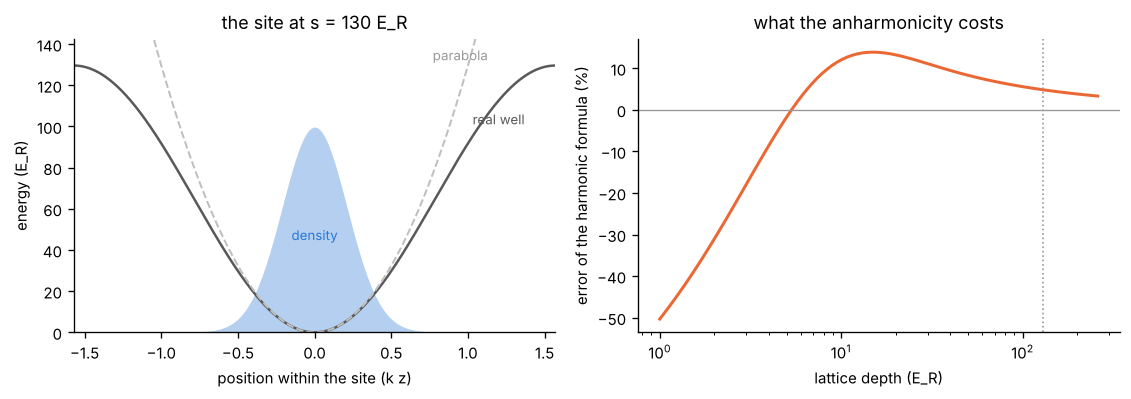

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))

a = ax[0]
a.plot(z_site, s_lat * np.sin(z_site) ** 2, color="0.35", lw=1.5)
a.plot(z_site, s_lat * z_site ** 2, color="0.75", lw=1.2, ls="--")
scale = s_lat / (1.3 * u_site.max() ** 2)
a.fill_between(z_site, 0, scale * u_site ** 2, color=PALETTE[0], alpha=0.35,
               lw=0)
a.set_ylim(0, s_lat * 1.1)
a.set_xlim(-math.pi / 2, math.pi / 2)
a.set_xlabel("position within the site (k z)")
a.set_ylabel("energy (E_R)")
a.set_title("the site at s = %.0f E_R" % s_lat)
a.annotate("real well", (1.2, s_lat * 0.78), color="0.35", fontsize=8,
           ha="center")
a.annotate("parabola", (0.95, s_lat * 1.02), color="0.6", fontsize=8,
           ha="center")
a.annotate("density", (0.0, scale * u_site.max() ** 2 * 0.45),
           color=PALETTE[0], fontsize=8, ha="center")

ss = np.logspace(0.0, math.log10(max(100.0, 2 * s_lat)), 90)
err = []
for s_ in ss:
    Eb = band_energies(s_, nmax=max(25, int(3 * math.sqrt(s_))))
    err.append(100 * (2 * math.sqrt(s_) / (Eb[1] - Eb[0]) - 1))
b = ax[1]
b.semilogx(ss, err, color=PALETTE[1], lw=1.8)
b.axhline(0, color="0.6", lw=0.8)
b.axvline(s_lat, color="0.6", ls=":", lw=1)
b.set_xlabel("lattice depth (E_R)")
b.set_ylabel("error of the harmonic formula (%)")
b.set_title("what the anharmonicity costs")
fig.tight_layout()
plt.show()

## 7. What is still worth measuring

For the notebook to return numbers you can trust, these are the parameters
worth measuring rather than estimating:

- **the lattice depth**, preferably by Bloch oscillations or amplitude
  modulation rather than from the beam power — the power estimate carries the
  uncertainty of the atomic constants and of the alignment;
- **the two in-plane frequencies**, by dipole oscillation, because the estimate
  from the waists ignores the Rayleigh range and any auxiliary trap;
- **the scattering length**, which depends on the magnetic field through the
  Feshbach resonance, and which is the knob that moves the effective in-plane
  interaction;
- **the atom number and the temperature** after loading into the lattice, not
  before.

Four warnings about what is inside:

1. the polarizability is modelled from the two D lines, which is good to a few
   per cent; the notebook prints its own static-limit value so you can see it
   land near the published 290 atomic units for potassium. A published value at
   your wavelength is better, and there is a field for it;
2. the Feshbach parameters are the broad potassium-39 resonance as commonly
   quoted, and are flagged to be checked against the original measurement
   before being used for anything but a first estimate;
3. the constant of the Berezinskii-Kosterlitz-Thouless criterion is left as an
   editable parameter precisely because its value should be confirmed against
   its source before it enters anything published;
4. the two-dimensional coupling is the weak-confinement form, and the notebook
   warns you when the scattering length stops being small compared with the
   axial oscillator length.

The expanded version of this calculation — the exact effective lattice
potential in the symmetric sector, a sweep across regimes, and the full
two-dimensional equation of state — lives in the project repository:

https://github.com/pemodest0/Low-energy-scattering